# Notebook 01 — EDA & Data Cleaning
Exploratory analysis of the Orange Disease dataset.

In [6]:
import os, sys
sys.path.insert(0, '..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image

DATA_DIR = '../data/raw'
CLASS_NAMES = ['blackspot', 'canker', 'fresh', 'grenning']


## 1. Class Distribution

In [7]:
def count_images(root):
    counts = {}
    for split in ['train', 'test']:
        for cls in CLASS_NAMES:
            p = os.path.join(root, split, cls)
            if os.path.isdir(p):
                counts[f'{split}/{cls}'] = len([f for f in os.listdir(p) if f.lower().endswith(('.jpg','.png','.jpeg'))])
    return counts

counts = count_images(DATA_DIR)
df = pd.DataFrame(list(counts.items()), columns=['Split_Class', 'Count'])
print(df.to_string(index=False))


    Split_Class  Count
train/blackspot    184
   train/canker    179
    train/fresh    281
 train/grenning    347
 test/blackspot     22
    test/canker     22
     test/fresh     33
  test/grenning     22


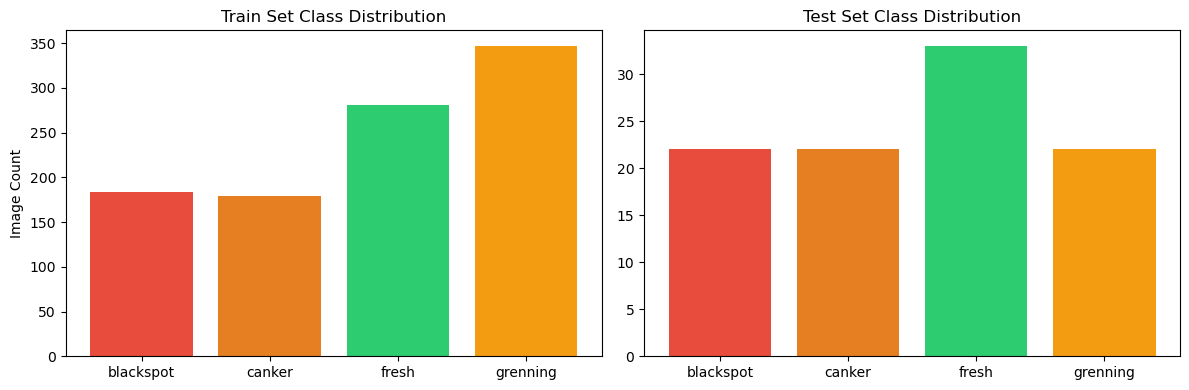


Class imbalance note: grenning has ~2x more train images than canker/blackspot.


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
train_counts = {k.split('/')[1]: v for k, v in counts.items() if k.startswith('train')}
test_counts  = {k.split('/')[1]: v for k, v in counts.items() if k.startswith('test')}

axes[0].bar(train_counts.keys(), train_counts.values(), color=['#e74c3c','#e67e22','#2ecc71','#f39c12'])
axes[0].set_title('Train Set Class Distribution')
axes[0].set_ylabel('Image Count')

axes[1].bar(test_counts.keys(), test_counts.values(), color=['#e74c3c','#e67e22','#2ecc71','#f39c12'])
axes[1].set_title('Test Set Class Distribution')

plt.tight_layout()
plt.savefig('../report/class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('\nClass imbalance note: grenning has ~2x more train images than canker/blackspot.')


## 2. Sample Images per Class

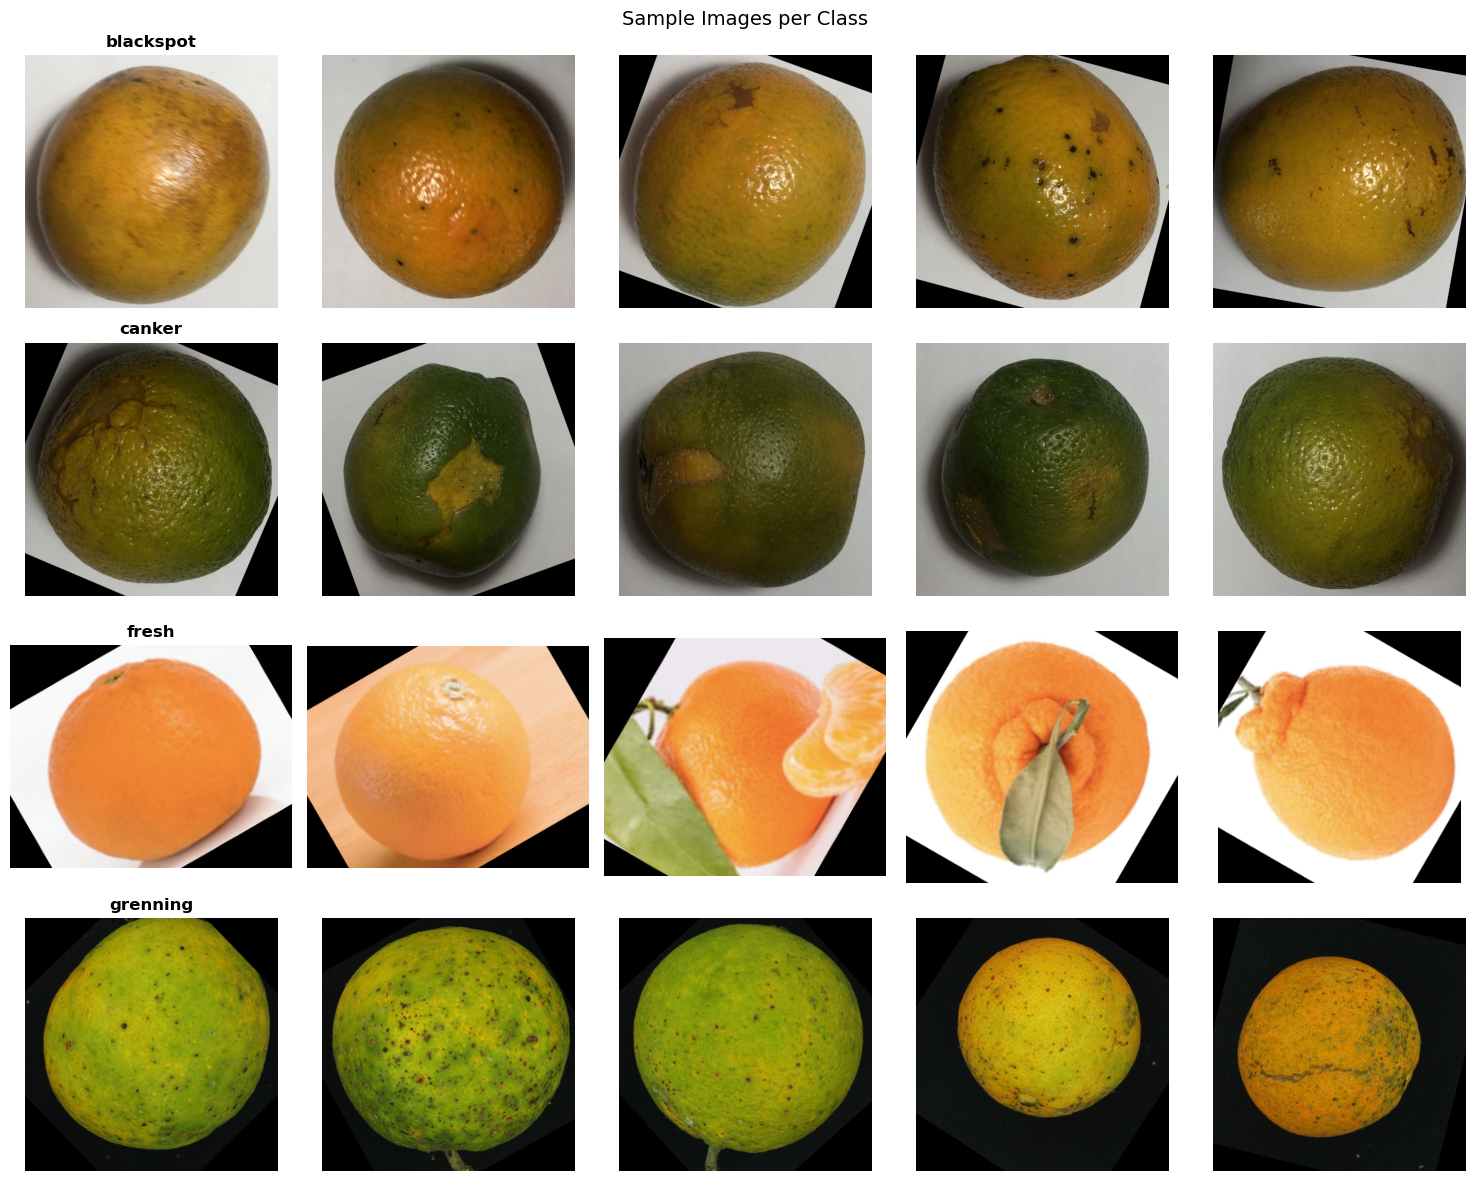

In [9]:
fig, axes = plt.subplots(4, 5, figsize=(15, 12))
for i, cls in enumerate(CLASS_NAMES):
    cls_dir = os.path.join(DATA_DIR, 'train', cls)
    files = sorted(os.listdir(cls_dir))[:5]
    for j, fname in enumerate(files):
        img = np.array(Image.open(os.path.join(cls_dir, fname)).convert('RGB'))
        axes[i][j].imshow(img)
        axes[i][j].axis('off')
        if j == 0:
            axes[i][j].set_title(cls, fontsize=12, fontweight='bold')
plt.suptitle('Sample Images per Class', fontsize=14)
plt.tight_layout()
plt.savefig('../report/sample_images.png', dpi=150, bbox_inches='tight')
plt.show()


## 3. Image Resolution & Channel Analysis

In [10]:
widths, heights = [], []
for cls in CLASS_NAMES:
    cls_dir = os.path.join(DATA_DIR, 'train', cls)
    for fname in os.listdir(cls_dir):
        if not fname.lower().endswith(('.jpg','.jpeg','.png')):
            continue
        try:
            img = Image.open(os.path.join(cls_dir, fname))
            w, h = img.size
            widths.append(w); heights.append(h)
        except:
            pass

print(f"Width  — min:{min(widths)}, max:{max(widths)}, mean:{np.mean(widths):.0f}")
print(f"Height — min:{min(heights)}, max:{max(heights)}, mean:{np.mean(heights):.0f}")
print(f"Total train images scanned: {len(widths)}")


Width  — min:144, max:800, mean:671
Height — min:138, max:800, mean:662
Total train images scanned: 991


## 4. Color Distribution per Class (HSV Hue Channel)

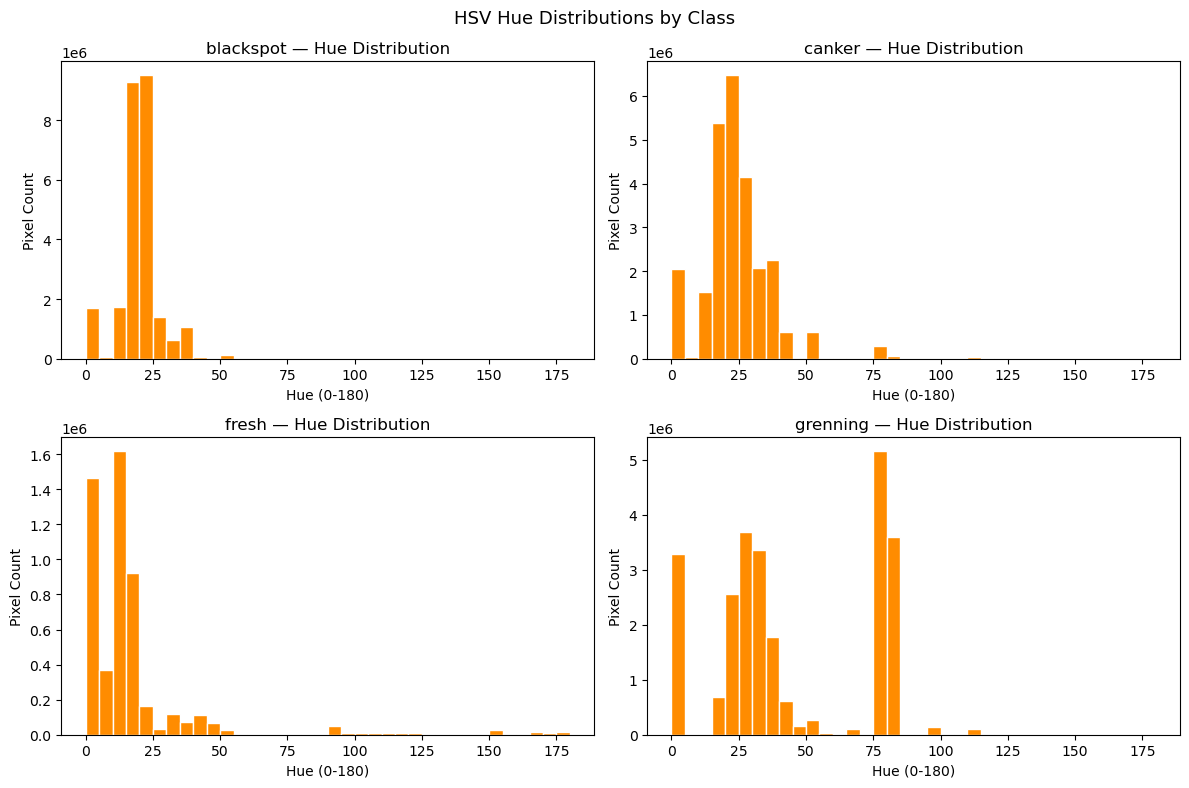

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, cls in zip(axes.flatten(), CLASS_NAMES):
    cls_dir = os.path.join(DATA_DIR, 'train', cls)
    hues = []
    for fname in list(os.listdir(cls_dir))[:40]:
        if not fname.lower().endswith(('.jpg','.jpeg','.png')):
            continue
        img_bgr = cv2.imread(os.path.join(cls_dir, fname))
        if img_bgr is None: continue
        hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
        hues.extend(hsv[:,:,0].flatten().tolist())
    ax.hist(hues, bins=36, range=(0,180), color='darkorange', edgecolor='white')
    ax.set_title(f'{cls} — Hue Distribution')
    ax.set_xlabel('Hue (0-180)')
    ax.set_ylabel('Pixel Count')

plt.suptitle('HSV Hue Distributions by Class', fontsize=13)
plt.tight_layout()
plt.savefig('../report/hue_distributions.png', dpi=150, bbox_inches='tight')
plt.show()


## 5. Dataset Bias & Outlier Notes

**Class Imbalance:**
- `grenning` has ~347 train images vs ~179 for `canker` — nearly 2× imbalance.
- Mitigation: stratified splits + class-weighted loss in DL training.

**Lighting & Background Variability:**
- Images are taken under different lighting conditions (outdoor vs indoor).
- Some images have white/dark backgrounds while others are natural.

**Resolution Variability:**
- Images vary widely in resolution; we resize all to 224×224 for consistency.

**Mislabeling Risk:**
- Early-stage blackspot can visually overlap with canker lesions — a known challenge.
